## Road Severity Prediction

# project overview

Road traffic accidents are a major concern for road safety authorities because they can result in injuries, fatalities, property damage and economic losses.

This project focuses on analysing road crash data to identify patterns and factors associated with crash severity. Using Exploratory Data Analysis (EDA) and machine learning techniques, the project aims to understand crash characteristics and develop predictive models that classify crashes according to their recorded severity index

## Project objectives
1. Analyse the distribution of road crashes across different periods of the day, seasons and weekdays.
2. Identify patterns and relationships between crash characteristics and severity.
3. Examine the influence of geographical variables such as distance to Nairobi and local crash density.
4. Develop machine learning models to predict the recorded crash severity class.
5. Evaluate model performance and identify the most useful predictive variables.
6. Provide recommendations that can support road safety planning and decision-making.

## Business problem
Road safety stakeholders need reliable information to understand crash patterns and identify circumstances associated with more severe crashes.

Without proper analysis, it can be difficult to identify patterns across time, seasons and geographical locations. This may limit the ability of road safety authorities to prioritize investigations, allocate resources and develop appropriate preventive interventions.

This project uses historical crash data to investigate these patterns and develop a machine learning model capable of predicting the recorded crash severity class.
2.2 Business objectives
The main business objective is to use historical road crash data to generate insights that can support road safety planning and decision-making.

**objectives include:**
- Identify periods associated with high numbers of crash records.
- Examine differences in severity across seasons and times of the day.
- Investigate geographical patterns in crash severity.
- Develop a predictive model to classify crash severity.
- Provide evidence-based recommendations for improving road safety managemen

## Key business questions
1. During which periods of the day are the most crashes recorded?

2. Which season has the highest number of crash records?

3. Are crash severity patterns different between weekdays and weekends?

4. Is distance to Nairobi associated with crash severity?

5. Does local crash density differ between severity classes?

6. Can machine learning predict the recorded severity class?

7. Which variables are most useful for predicting crash severity?

## Data understanding

This dataset was sourced from [world bank](https://microdata.worldbank.org/index.php/catalog/6249)

## importing libraries

In [1]:


import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, RocCurveDisplay,
    PrecisionRecallDisplay
)
from sklearn.inspection import permutation_importance
import joblib

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 4. Load the dataset

In [2]:
df = pd.read_csv(r"C:\Users\USER\Downloads\processed_crash_data.csv")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (25252, 17)


,n_crash_reports,contains_fatality_words,contains_pedestrian_words,year,day_of_week,hour,day,weekday,month,is_weekend,day_part,distance_to_nairobi,contains_vehicle_words,severity_index,local_crash_density,season,fatality_mention_ratio
0,1,0,0,2018.0,Wednesday,20.0,6.0,2.0,6.0,0,evening,7.165499,0,0,3303,dry,0.054249
1,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,56.743166,0,1,1,transitional,0.062719
2,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,27.398293,0,0,481,transitional,0.062719
3,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,60.469275,0,0,5,transitional,0.062719
4,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,4.287275,0,1,7019,transitional,0.062719


## 5. Understand the dataset

In [3]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.rename("data_type").to_frame())

print("\nSummary statistics:")
display(df.describe(include="all").T)

print("\nTarget distribution:")
display(df["severity_index"].value_counts(dropna=False).rename("count").to_frame())

Rows and columns: (25252, 17)

Column names:
['n_crash_reports', 'contains_fatality_words', 'contains_pedestrian_words', 'year', 'day_of_week', 'hour', 'day', 'weekday', 'month', 'is_weekend', 'day_part', 'distance_to_nairobi', 'contains_vehicle_words', 'severity_index', 'local_crash_density', 'season', 'fatality_mention_ratio']

Data types:


,data_type
n_crash_reports,int64
contains_fatality_words,int64
contains_pedestrian_words,int64
year,float64
day_of_week,str
hour,float64
day,float64
weekday,float64
month,float64
is_weekend,int64



Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
n_crash_reports,25252.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
contains_fatality_words,25252.0,NaN,NaN,NaN,0.06051,0.238434,0.0,0.0,0.0,0.0,1.0
contains_pedestrian_words,25252.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
year,10259.0,NaN,NaN,NaN,2017.082757,2.730444,2012.0,2015.0,2017.0,2019.0,2023.0
day_of_week,10259,7,Thursday,1527,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hour,10259.0,NaN,NaN,NaN,13.134321,5.542625,0.0,8.0,13.0,18.0,23.0
day,10259.0,NaN,NaN,NaN,6.618871,3.451835,1.0,4.0,7.0,10.0,12.0
weekday,10259.0,NaN,NaN,NaN,3.015888,1.99381,0.0,1.0,3.0,5.0,6.0
month,10259.0,NaN,NaN,NaN,6.508237,3.446695,1.0,3.0,7.0,9.0,12.0
is_weekend,25252.0,NaN,NaN,NaN,0.116387,0.320695,0.0,0.0,0.0,0.0,1.0



Target distribution:


,count
severity_index,
0,23724
1,1528


### data-quality observations

The uploaded file contains **25,252 rows and 17 columns**. In the supplied copy:
- `severity_index` has two classes: 0 and 1.
- The class distribution is imbalanced; class 1 is much less common.
- Several date/time columns (`year`, `day_of_week`, `hour`, `day`, `weekday`, `month`) have substantial missingness.
- `n_crash_reports`, `contains_pedestrian_words`, and `contains_vehicle_words` are constant in this file and cannot help distinguish records.
- `contains_fatality_words` exactly matches the target in this file. It is excluded from predictive features because it would reveal the target rather than provide a fair prediction.
- `fatality_mention_ratio` is also excluded because it is derived from fatality-related text and may encode information that would not be available before the outcome is assessed.


In [4]:
print("Missing values (count and percentage):")
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)
display(missing)

print("Constant columns:")
constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print(constant_cols)

if "contains_fatality_words" in df.columns:
    print(
        "contains_fatality_words equals severity_index for every row:",
        df["contains_fatality_words"].equals(df["severity_index"])
    )

print("\nTarget proportions:")
display((df["severity_index"].value_counts(normalize=True) * 100).round(2).rename("percent").to_frame())

Missing values (count and percentage):


,missing_count,missing_percent
day_of_week,14993,59.37
weekday,14993,59.37
year,14993,59.37
day,14993,59.37
hour,14993,59.37
month,14993,59.37
n_crash_reports,0,0.00
contains_fatality_words,0,0.00
contains_pedestrian_words,0,0.00
is_weekend,0,0.00


Constant columns:
['n_crash_reports', 'contains_pedestrian_words', 'contains_vehicle_words']
contains_fatality_words equals severity_index for every row: True

Target proportions:


,percent
severity_index,
0,93.95
1,6.05


## 6. Data cleaning and preparation

Cleaning decisions:
- Remove exact duplicate rows, if any.
- Remove records with a missing target because they cannot be used for supervised learning.
- Ensure the target is represented as an integer class.
- Do not replace missing date/time values with invented values. Missing numeric and categorical predictors are imputed inside each model pipeline using training data only.
- Remove constant columns and likely leakage variables from the model features.
- Keep `severity_index` as the target, not as a predictor.

**Prediction scope:** The model uses available contextual variables such as time, season, distance to Nairobi, and local crash density. This is a modelling exercise on the supplied processed dataset, not a validated operational road-safety system.

In [5]:
data = df.copy()

before_rows = len(data)
data = data.drop_duplicates()
print("Duplicate rows removed:", before_rows - len(data))

data = data.dropna(subset=["severity_index"]).copy()
data["severity_index"] = pd.to_numeric(data["severity_index"], errors="coerce")
data = data.dropna(subset=["severity_index"]).copy()
data["severity_index"] = data["severity_index"].astype(int)

print("Cleaned modelling data shape:", data.shape)
print("Target values:", sorted(data["severity_index"].unique()))

Duplicate rows removed: 9374
Cleaned modelling data shape: (15878, 17)
Target values: [np.int64(0), np.int64(1)]


## 7. Exploratory Data Analysis (EDA)

### 7.1 Target distribution (univariate)

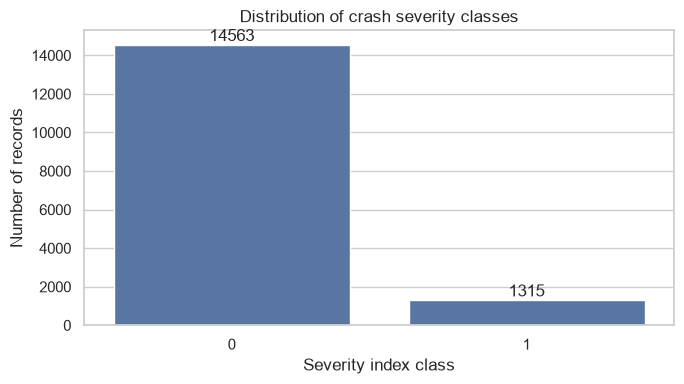

In [6]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=data, x="severity_index")
ax.set(title="Distribution of crash severity classes", xlabel="Severity index class", ylabel="Number of records")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

**Interpretation:** Compare the bar heights. A much smaller class 1 count indicates class imbalance. In an imbalanced problem, accuracy alone can be misleading; recall, precision, F1-score, balanced accuracy, and precision-recall AUC are also important.

### 7.2 Crashes by hour (univariate)

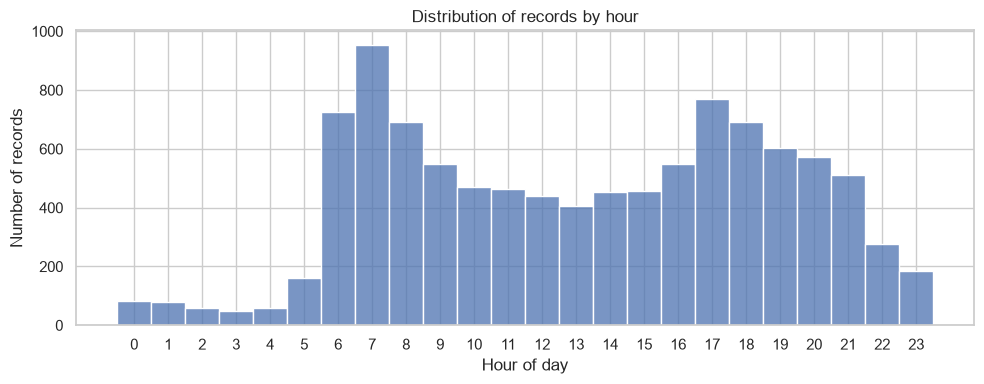

In [7]:
if "hour" in data.columns:
    plt.figure(figsize=(10, 4))
    sns.histplot(data=data, x="hour", bins=np.arange(-0.5, 24.5, 1), discrete=True)
    plt.title("Distribution of records by hour")
    plt.xlabel("Hour of day")
    plt.ylabel("Number of records")
    plt.xticks(range(24))
    plt.tight_layout()
    plt.show()

### 7.3 Distance to Nairobi (univariate)

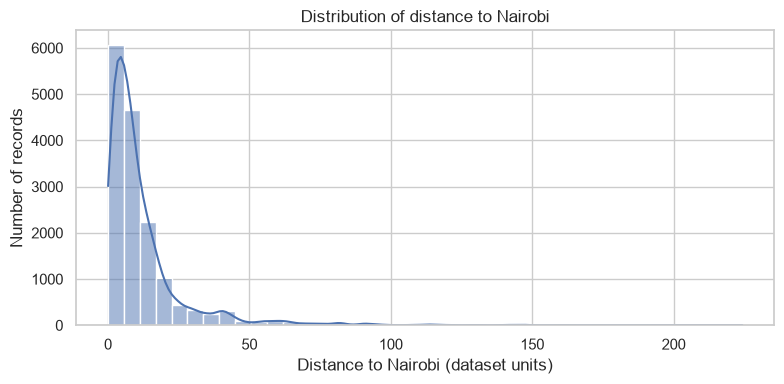

In [8]:
plt.figure(figsize=(8, 4))
sns.histplot(data=data, x="distance_to_nairobi", bins=40, kde=True)
plt.title("Distribution of distance to Nairobi")
plt.xlabel("Distance to Nairobi (dataset units)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

### 7.4 Severity class by season (bivariate)

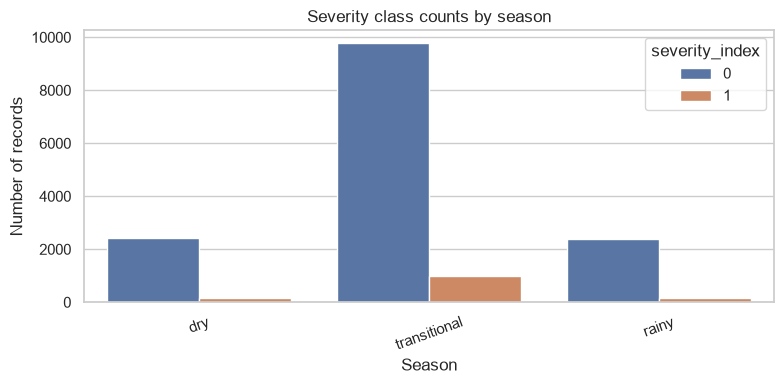

In [9]:
if "season" in data.columns:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=data, x="season", hue="severity_index")
    plt.title("Severity class counts by season")
    plt.xlabel("Season")
    plt.ylabel("Number of records")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

### 7.5 Severity class by day part (bivariate)

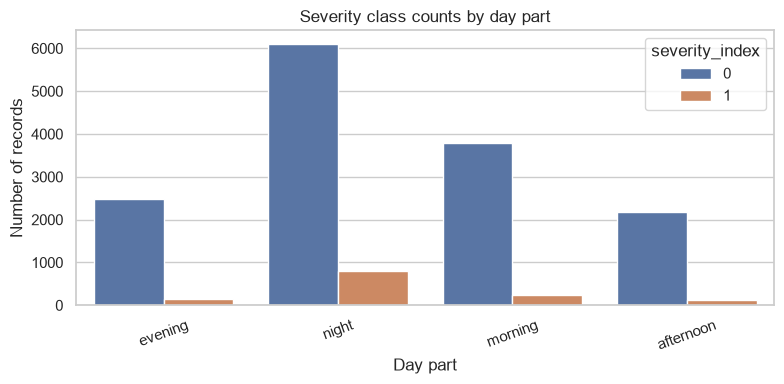

In [10]:
if "day_part" in data.columns:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=data, x="day_part", hue="severity_index")
    plt.title("Severity class counts by day part")
    plt.xlabel("Day part")
    plt.ylabel("Number of records")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

### 7.6 Local crash density by severity (bivariate)

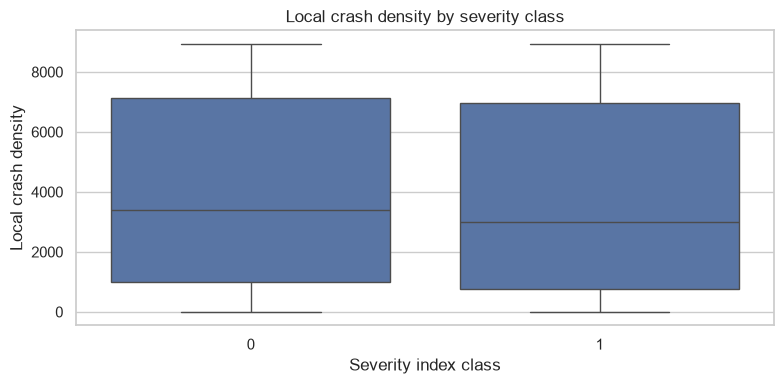

In [11]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=data, x="severity_index", y="local_crash_density")
plt.title("Local crash density by severity class")
plt.xlabel("Severity index class")
plt.ylabel("Local crash density")
plt.tight_layout()
plt.show()

### 7.7 Distance and local crash density by severity (multivariate)

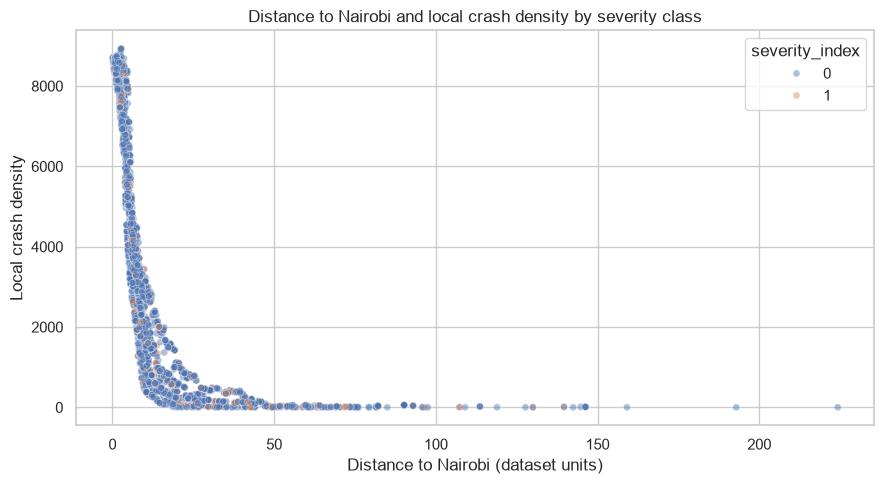

In [12]:
sample_plot = data.sample(min(5000, len(data)), random_state=RANDOM_STATE)
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=sample_plot, x="distance_to_nairobi", y="local_crash_density",
    hue="severity_index", alpha=0.45, s=25
)
plt.title("Distance to Nairobi and local crash density by severity class")
plt.xlabel("Distance to Nairobi (dataset units)")
plt.ylabel("Local crash density")
plt.tight_layout()
plt.show()

### 7.8 Hour, season, and severity (multivariate)

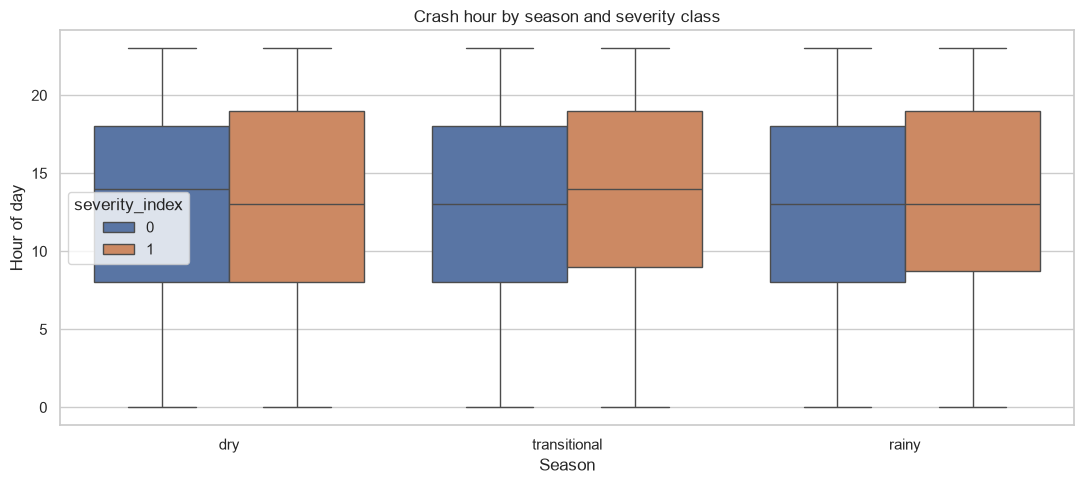

In [13]:
if {"hour", "season", "severity_index"}.issubset(data.columns):
    plt.figure(figsize=(11, 5))
    sns.boxplot(data=data, x="season", y="hour", hue="severity_index")
    plt.title("Crash hour by season and severity class")
    plt.xlabel("Season")
    plt.ylabel("Hour of day")
    plt.tight_layout()
    plt.show()

### 7.9 Correlation heatmap (numeric variables)

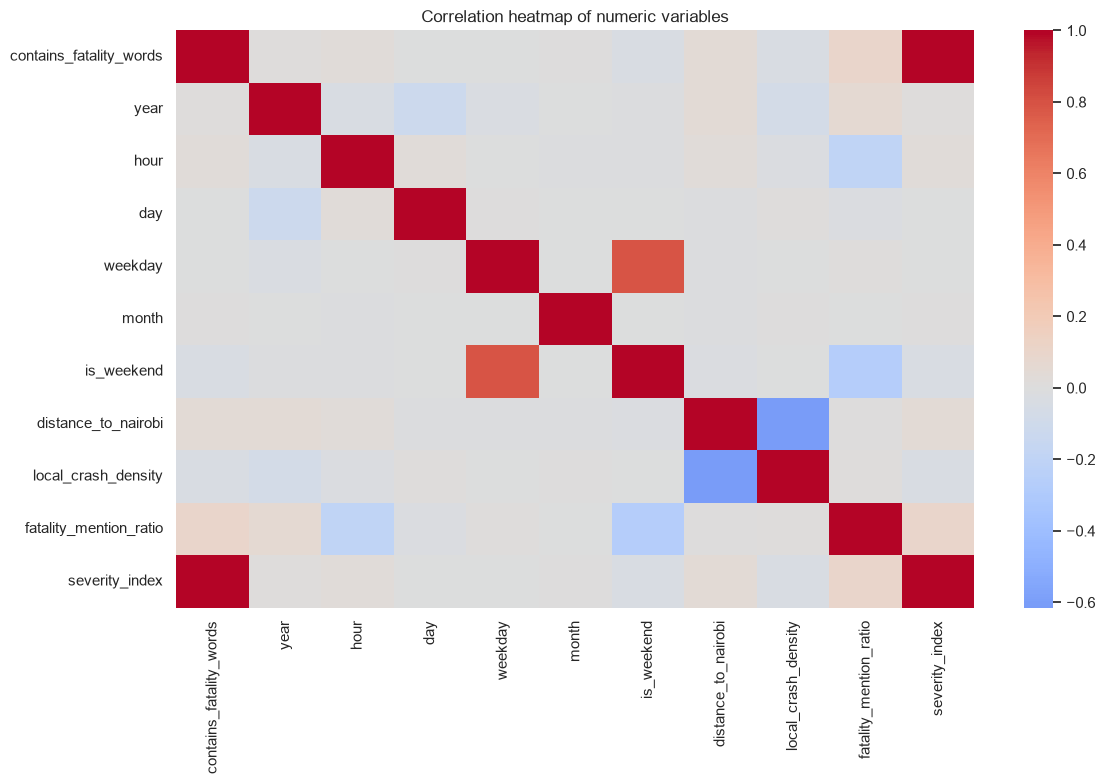

In [14]:
numeric_for_corr = data.select_dtypes(include=np.number).drop(columns=["severity_index"], errors="ignore")
# Remove constant numeric columns from the heatmap.
numeric_for_corr = numeric_for_corr.loc[:, numeric_for_corr.nunique(dropna=True) > 1]
if not numeric_for_corr.empty:
    corr_data = numeric_for_corr.copy()
    corr_data["severity_index"] = data["severity_index"]
    plt.figure(figsize=(12, 8))
    sns.heatmap(corr_data.corr(numeric_only=True), cmap="coolwarm", center=0, annot=False)
    plt.title("Correlation heatmap of numeric variables")
    plt.tight_layout()
    plt.show()

## 8. Define the prediction task and avoid target leakage

The target is `severity_index`. The following columns are deliberately not used as predictors:
- `severity_index`: the target itself.
- `contains_fatality_words`: in this file it exactly equals the target, so it is direct leakage.
- `fatality_mention_ratio`: fatality-text-derived information may only be known after the crash description/outcome is available.
- `n_crash_reports`, `contains_pedestrian_words`, and `contains_vehicle_words`: constant columns in this file.

If the intended deployment predicts severity before a report is written, all text-derived variables should be excluded. If the real project instead classifies an already-written crash report, define that task explicitly and ensure the text features are not simply copies of the label.

In [15]:
target = "severity_index"
leakage_or_unusable = [
    "severity_index",
    "contains_fatality_words",
    "fatality_mention_ratio",
    "n_crash_reports",
    "contains_pedestrian_words",
    "contains_vehicle_words"
]
feature_cols = [c for c in data.columns if c not in leakage_or_unusable]

# Remove any other constant predictors, based on this cleaned data.
feature_cols = [c for c in feature_cols if data[c].nunique(dropna=True) > 1]

X = data[feature_cols].copy()
y = data[target].copy()

print("Predictor columns:", feature_cols)
print("\nX shape:", X.shape, "| y shape:", y.shape)
print("\nClass counts:")
display(y.value_counts().to_frame("records"))

Predictor columns: ['year', 'day_of_week', 'hour', 'day', 'weekday', 'month', 'is_weekend', 'day_part', 'distance_to_nairobi', 'local_crash_density', 'season']

X shape: (15878, 11) | y shape: (15878,)

Class counts:


,records
severity_index,
0,14563
1,1315


## 9. Train/test split and preprocessing

A stratified split preserves the class proportions in both sets. Numeric variables are median-imputed and scaled for logistic regression. Categorical variables are imputed with the most frequent category and one-hot encoded. Preprocessing is fitted only on training data to avoid data leakage.

In [16]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())
print("\nTesting target proportions:")
display(y_test.value_counts(normalize=True).rename("proportion").to_frame())

Training rows: 12702
Testing rows: 3176

Training target proportions:


,proportion
severity_index,
0,0.917178
1,0.082822



Testing target proportions:


,proportion
severity_index,
0,0.917191
1,0.082809


## 10. Train classification models

Models:
1. **Dummy classifier:** majority-class baseline; shows how a trivial model performs.
2. **Logistic regression:** interpretable linear classification baseline, with class weighting.
3. **Random forest:** captures nonlinear relationships and feature interactions.

`class_weight="balanced"` gives additional weight to the less common class. Model performance must still be evaluated on the untouched test set.

In [17]:
models = {
    "Dummy baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

pipelines = {
    name: Pipeline(steps=[("preprocess", preprocessor), ("model", model)])
    for name, model in models.items()
}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    print(f"Trained: {name}")

Trained: Dummy baseline
Trained: Logistic regression
Trained: Random forest


## 11. Evaluate and compare models

We report:
- **Accuracy:** proportion of all predictions that are correct.
- **Balanced accuracy:** average recall across the two classes.
- **Precision for class 1:** of records predicted as class 1, how many truly belong to class 1.
- **Recall for class 1:** of all actual class 1 records, how many the model identifies.
- **F1 for class 1:** harmonic mean of class 1 precision and recall.
- **ROC-AUC:** ranking performance across thresholds.
- **PR-AUC / average precision:** particularly informative when the positive class is rare.

For a safety-related application, false negatives can be costly, but the acceptable trade-off must be set with domain experts.

In [18]:
#evaluate each model using the same test dataset.
def evaluate_model(name, pipe, X_eval, y_eval):
    pred = pipe.predict(X_eval)
    
# dictionary to store model name and prediction results
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Balanced accuracy": balanced_accuracy_score(y_eval, pred),
        "Precision (class 1)": precision_score(y_eval, pred, pos_label=1, zero_division=0),
        "Recall (class 1)": recall_score(y_eval, pred, pos_label=1, zero_division=0),
        "F1 (class 1)": f1_score(y_eval, pred, pos_label=1, zero_division=0)
    }
    if hasattr(pipe, "predict_proba") and len(np.unique(y_eval)) == 2:
        prob = pipe.predict_proba(X_eval)[:, 1]
        row["ROC-AUC"] = roc_auc_score(y_eval, prob)
        row["PR-AUC"] = average_precision_score(y_eval, prob)
    else:
        row["ROC-AUC"] = np.nan
        row["PR-AUC"] = np.nan
    return row

results = pd.DataFrame([
    evaluate_model(name, pipe, X_test, y_test)
    for name, pipe in pipelines.items()
]).set_index("Model").sort_values("F1 (class 1)", ascending=False)

display(results.round(4))

,Accuracy,Balanced accuracy,Precision (class 1),Recall (class 1),F1 (class 1),ROC-AUC,PR-AUC
Model,,,,,,,
Logistic regression,0.5677,0.5862,0.1119,0.6084,0.1890,0.5924,0.1195
Random forest,0.8344,0.5361,0.1317,0.1787,0.1516,0.5966,0.1109
Dummy baseline,0.9172,0.5000,0.0000,0.0000,0.0000,0.5000,0.0828


### 11.1 Classification report for the best non-baseline model

In [19]:
candidate_names = [n for n in pipelines if n != "Dummy baseline"]
best_name = results.loc[candidate_names, "F1 (class 1)"].idxmax()
best_model = pipelines[best_name]
best_pred = best_model.predict(X_test)

print("Selected model:", best_name)
print(classification_report(y_test, best_pred, zero_division=0))

Selected model: Logistic regression
              precision    recall  f1-score   support

           0       0.94      0.56      0.71      2913
           1       0.11      0.61      0.19       263

    accuracy                           0.57      3176
   macro avg       0.53      0.59      0.45      3176
weighted avg       0.87      0.57      0.66      3176



### 11.2 Confusion matrix

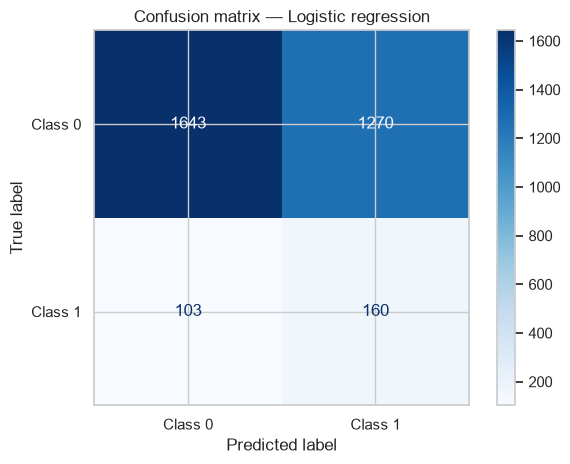

In [20]:
cm = confusion_matrix(y_test, best_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Class 0", "Class 1"])
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion matrix — {best_name}")
plt.tight_layout()
plt.show()

### 11.3 ROC and precision-recall curves

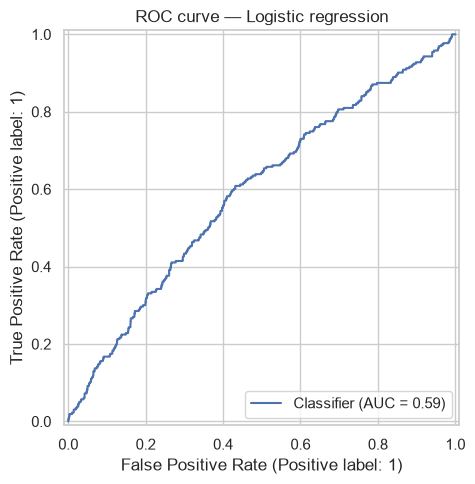

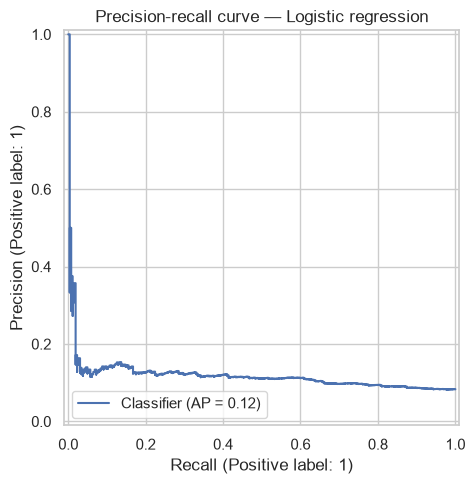

In [21]:
if hasattr(best_model, "predict_proba"):
    best_prob = best_model.predict_proba(X_test)[:, 1]

    fig, ax = plt.subplots(figsize=(6, 5))
    RocCurveDisplay.from_predictions(y_test, best_prob, ax=ax)
    ax.set_title(f"ROC curve — {best_name}")
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(6, 5))
    PrecisionRecallDisplay.from_predictions(y_test, best_prob, ax=ax)
    ax.set_title(f"Precision-recall curve — {best_name}")
    plt.tight_layout()
    plt.show()

## 12. Threshold analysis

The default classification threshold is 0.50. Lowering it may increase recall for class 1 while reducing precision. The table below shows the trade-off at several thresholds. Select a threshold based on the real cost of missed severe crashes versus false alarms, not simply the largest metric.

In [22]:
from sklearn.metrics import precision_recall_fscore_support

if hasattr(best_model, "predict_proba"):
    threshold_rows = []
    for threshold in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
        threshold_pred = (best_prob >= threshold).astype(int)
        p, r, f, _ = precision_recall_fscore_support(
            y_test, threshold_pred, labels=[1], zero_division=0
        )
        threshold_rows.append({
            "Threshold": threshold,
            "Precision class 1": p[0],
            "Recall class 1": r[0],
            "F1 class 1": f[0]
        })
    threshold_results = pd.DataFrame(threshold_rows)
    display(threshold_results.round(3))

,Threshold,Precision class 1,Recall class 1,F1 class 1
0,0.2,0.083,1.000,0.153
1,0.3,0.083,1.000,0.153
2,0.4,0.097,0.753,0.171
3,0.5,0.112,0.608,0.189
4,0.6,0.119,0.232,0.157
5,0.7,0.208,0.019,0.035


## 13. Feature importance

Permutation importance measures how much the chosen model's score decreases when one feature is shuffled. It is calculated on the test set using balanced accuracy. It describes model reliance, not causation.

,feature,importance_mean,importance_std
7,day_part,0.086897,0.012614
8,distance_to_nairobi,0.003332,0.001840
10,season,0.000965,0.000242
2,hour,0.000746,0.001382
3,day,0.000586,0.000926
6,is_weekend,0.000000,0.000000
5,month,-0.000150,0.000103
1,day_of_week,-0.000231,0.000926
4,weekday,-0.000343,0.000271
0,year,-0.000474,0.000650


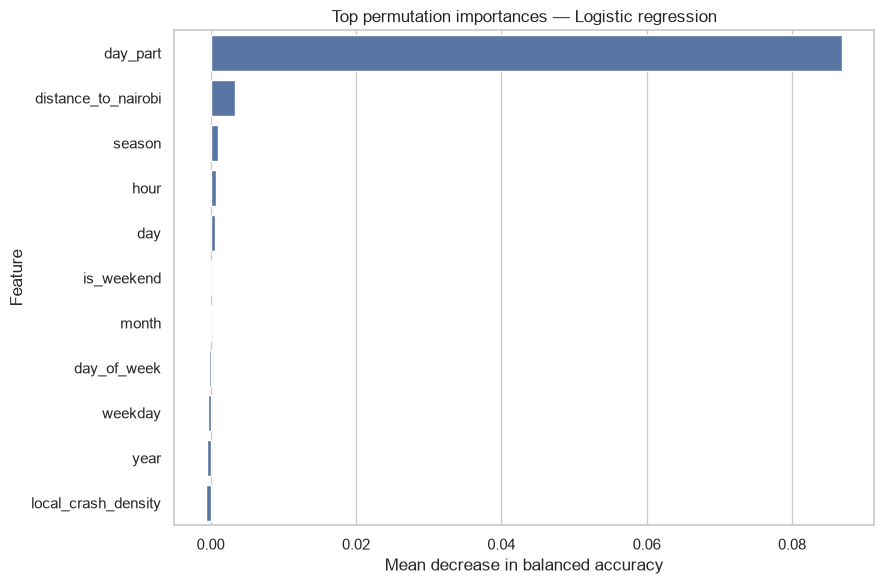

In [23]:
perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=8, random_state=RANDOM_STATE,
    scoring="balanced_accuracy", n_jobs=-1
)
importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance.head(15))
plt.figure(figsize=(9, 6))
sns.barplot(data=importance.head(15), x="importance_mean", y="feature")
plt.title(f"Top permutation importances — {best_name}")
plt.xlabel("Mean decrease in balanced accuracy")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [24]:
class_counts = y.value_counts().sort_index()
class_pct = (y.value_counts(normalize=True).sort_index() * 100).round(2)

print("Class counts:")
for cls in class_counts.index:
    print(f"Class {cls}: {class_counts[cls]:,} records ({class_pct[cls]}%)")

print("\nSelected model:", best_name)
print("Test metrics:")
display(results.loc[[best_name]].round(4))

print("\nTop five permutation features:")
display(importance.head(5).round(4))

Class counts:
Class 0: 14,563 records (91.72%)
Class 1: 1,315 records (8.28%)

Selected model: Logistic regression
Test metrics:


,Accuracy,Balanced accuracy,Precision (class 1),Recall (class 1),F1 (class 1),ROC-AUC,PR-AUC
Model,,,,,,,
Logistic regression,0.5677,0.5862,0.1119,0.6084,0.189,0.5924,0.1195



Top five permutation features:


,feature,importance_mean,importance_std
7,day_part,0.0869,0.0126
8,distance_to_nairobi,0.0033,0.0018
10,season,0.0010,0.0002
2,hour,0.0007,0.0014
3,day,0.0006,0.0009


## 14. Recommendations

Use these as cautious project recommendations and revise them after reviewing the actual plots and model outputs:

- Prioritize monitoring periods and locations that the EDA identifies as having higher crash-record counts or density.
- Investigate why date/time metadata is missing for a large share of records; better metadata quality may improve analysis.
- Do not use fatality-text indicators as predictors for an early-warning model if they are only available after the crash or directly encode the target.
- Evaluate models using class 1 recall, precision, F1, and PR-AUC, not accuracy alone.
- Before operational use, validate the model on a later time period or a separate geographic area and assess performance across relevant groups.
- Consult road-safety experts to define the meaning of the target, the costs of false negatives/false positives, and an appropriate alert threshold.

## 15. Limitations

- The meaning and construction of `severity_index` are not defined in the CSV itself.
- Many date/time fields are missing.
- Some columns are constant and therefore uninformative in this dataset.
- The data is imbalanced.
- The supplied file is processed data; the notebook cannot verify how the original crash records were collected, sampled, or transformed.
- A random train/test split can overestimate performance when nearby records or records from the same time period are highly related. A future time-based validation split is preferable if a reliable date field is available.
- The model identifies statistical patterns, not causal factors.
- This project is educational and is not a substitute for a validated road-safety decision system.

## 16. Save the trained model

The saved pipeline includes preprocessing and the trained classifier. It expects input columns with the same names and compatible data types as the training features.

In [25]:
MODEL_PATH = Path("road_crash_severity_model.joblib")
joblib.dump(
    {"pipeline": best_model, "feature_columns": feature_cols, "target": target},
    MODEL_PATH
)
print("Saved model to:", MODEL_PATH.resolve())

Saved model to: C:\Users\USER\Downloads\road crash severity prediction\road_crash_severity_model.joblib


## 17. Example: make a prediction for a new record

Replace the example values with a real record. Any missing fields are handled by the pipeline. Do not include excluded leakage columns.

In [26]:
# Example row uses only the model's selected predictor columns.
example_record = X_train.iloc[[0]].copy()

example_class = best_model.predict(example_record)[0]
print("Predicted severity_index class:", example_class)

if hasattr(best_model, "predict_proba"):
    example_probability = best_model.predict_proba(example_record)[0]
    print("Class probabilities:", dict(zip(best_model.classes_, example_probability.round(4))))

Predicted severity_index class: 1
Class probabilities: {np.int64(0): np.float64(0.4457), np.int64(1): np.float64(0.5543)}
